# 13 · Extra checks: labels, confidence, strict thresholds, less popular sites, and an allowlist

**In one sentence:** five quick checks that answer the questions an examiner (or a real user) would ask next, using models and results we already have.

| Check | Question |
|---|---|
| 1. Label audit | Is `google.com` the only popular site labelled phishing, or a pattern? |
| 2. Calibration | When a model says "90% phishing", is it right 90% of the time? |
| 3. Strict threshold | How much phishing is caught if we allow only 1 false alarm per 100, or per 1,000? |
| 4. Less popular sites | Our earlier tests used *popular* sites. What about ordinary ones? |
| 5. Allowlist | Does "never flag a well-known site" fix the false alarms, and what does it cost? |

Nothing here retrains the main models, except one quick n-gram model in check 4. Code: `src/phishguard/audit.py` (with tests). Decision: D19.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from phishguard.audit import (expected_calibration_error, popular_owner_labels, rates_at, reliability_table,
                              threshold_for_fpr, with_allowlist)
from phishguard.data import TARGET, load_clean
from phishguard.datafix import build_pools, make_sets
from phishguard.evaluate import best_threshold
from phishguard.experiment import load_predictions
from phishguard.modeling import char_ngram_model
from phishguard.robustness import EXTERNAL_DIR
from phishguard.serving import Checker, _hybrid_proba
from phishguard.split import site_owner

df = load_clean()
y = df[TARGET]
top20k = pd.read_csv(EXTERNAL_DIR / "tranco_GQ3QK_top20k.csv")
top100k = pd.read_csv(EXTERNAL_DIR / "tranco_GQ3QK_top100k.csv.gz")
long_tail = pd.read_csv(EXTERNAL_DIR / "tranco_GQ3QK_rank100k-1M_sample20k.csv")["domain"]

## Check 1 · Which popular websites does PhiUSIIL label as phishing?

We take every **site owner** that is a popular real website (in the Tranco top 20,000) and has at least 20 rows in PhiUSIIL, and look at how many of its rows are labelled phishing.

In [2]:
owners = popular_owner_labels(df, TARGET, top20k)
mostly_phishing = owners[owners["phishing_share"] >= 0.5]
print(f"{len(owners)} popular owners with ≥ 20 rows; {len(mostly_phishing)} of them are mostly labelled phishing "
      f"({int(mostly_phishing['rows'].sum()):,} rows)")
mostly_phishing.head(15).round(2)

68 popular owners with ≥ 20 rows; 44 of them are mostly labelled phishing (6,932 rows)


,rows,phishing_share,tranco_rank
ipfs.io,1441,1.0,16056
google.com,782,1.0,1
godaddysites.com,769,1.0,6363
weebly.com,552,1.0,338
tw1.ru,407,1.0,4662
windows.net,326,1.0,59
regruhosting.ru,296,1.0,16430
myportfolio.com,230,1.0,4991
aliyuncs.com,219,1.0,120
myqcloud.com,183,1.0,468


**How to read this:** these aren't phishing *companies*. They are **shared services**: file hosting (`ipfs.io`), website builders (`weebly.com`, `godaddysites.com`), cloud storage (`windows.net`, `aliyuncs.com`), link shorteners (`bit.ly`, `tinyurl.com`) and Google Docs/Sites (`google.com`). Attackers put phishing pages *on* them, and the dataset labels the whole link as phishing.

For a model that reads only the domain, that's a real problem: a phishing page on `weebly.com` and an honest one look identical. So `google.com` (D16) was not a one-off. It's a pattern across the most-used hosting services.

## Check 2 · Are the probabilities honest? (calibration)

A model is **calibrated** if, among all links it gives about 0.9, roughly 90% really are phishing. We group the seed-42 **test** links into 10 bins by predicted probability and compare the average prediction with the real share of phishing. The **expected calibration error (ECE)** is the average gap, weighted by how many links each bin holds: 0 is perfect.

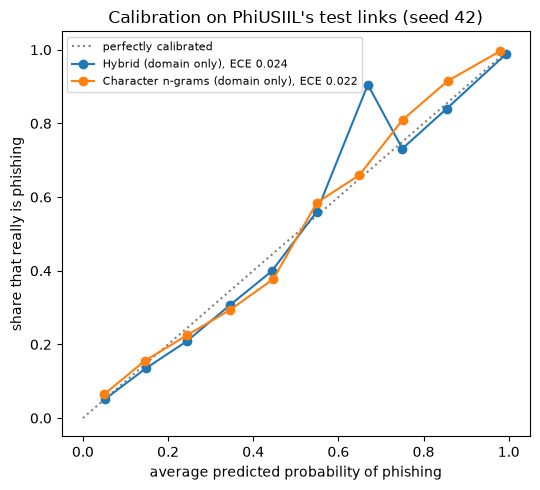

In [3]:
models = {"Hybrid (domain only)": ("m5_hybrid", "Hybrid CNN + features | domain only"),
          "Character n-grams (domain only)": ("m3_views", "Char n-gram LogReg | domain only")}
preds = {name: load_predictions(*key) for name, key in models.items()}

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], color="grey", linestyle=":", label="perfectly calibrated")
for name, p in preds.items():
    y_test = y.loc[p["test_idx"]].to_numpy()
    table = reliability_table(y_test, p["test_prob"])
    ece = expected_calibration_error(y_test, p["test_prob"])
    ax.plot(table["predicted"], table["observed"], marker="o", label=f"{name}, ECE {ece:.3f}")
ax.set_xlabel("average predicted probability of phishing")
ax.set_ylabel("share that really is phishing")
ax.set_title("Calibration on PhiUSIIL's test links (seed 42)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**How to read this:** both lines stay close to the diagonal, and the average gap is about 2 points. **Inside PhiUSIIL, the probabilities are honest.**

But calibration only holds for data like the training data. On real popular sites with a subdomain, the same model says "phishing" for most of them (Milestone 7), and below we see how confident it is when it's wrong:

In [4]:
checker = Checker.load()
pools = build_pools(df)
crux_sub = pools["crux_subdomain"]
crux_prob = _hybrid_proba(checker.hybrid, crux_sub)
wrong = crux_prob >= checker.numbers["models"]["hybrid"]["threshold"]
print(f"{len(crux_sub):,} popular legitimate sites with a subdomain: {wrong.mean():.0%} flagged as phishing; "
      f"of those, {(crux_prob[wrong] >= 0.9).mean():.0%} with probability ≥ 0.9")

1,448 popular legitimate sites with a subdomain: 80% flagged as phishing; of those, 77% with probability ≥ 0.9


Most of the wrong answers come with a probability of 0.9 or more. **A calibrated model is not a safe model:** its confidence means something only on data like its training data. Under distribution shift, it is confidently wrong.

## Check 3 · How much is caught with few false alarms?
So far each threshold was chosen to make the **fewest total mistakes** on validation. A browser warning has a different job: it must almost never warn on a real site. So we choose the threshold on **validation** for a target false-alarm rate (1 in 100, then 1 in 1,000) and measure on **test**.

In [5]:
rows = []
for name, p in preds.items():
    y_val, y_test = y.loc[p["val_idx"]].to_numpy(), y.loc[p["test_idx"]].to_numpy()
    rows.append({"model": name, "target": "fewest mistakes (as before)", "threshold": float(p["threshold"]),
                 **rates_at(y_test, p["test_prob"], float(p["threshold"]))})
    for max_fpr in (0.01, 0.001):
        t = threshold_for_fpr(y_val, p["val_prob"], max_fpr)
        rows.append({"model": name, "target": f"≤ {max_fpr:.1%} false alarms", "threshold": t,
                     **rates_at(y_test, p["test_prob"], t)})
operating = pd.DataFrame(rows).set_index(["model", "target"])
(operating * [1, 100, 100]).round(2).rename(columns={"caught": "caught (%)", "false_alarms": "false alarms (%)"})

threshold  \
model                           target                                   
Hybrid (domain only)            fewest mistakes (as before)       0.55   
                                ≤ 1.0% false alarms               0.75   
                                ≤ 0.1% false alarms               0.99   
Character n-grams (domain only) fewest mistakes (as before)       0.52   
                                ≤ 1.0% false alarms               0.74   
                                ≤ 0.1% false alarms               0.93   

                                                             caught (%)  \
model                           target                                    
Hybrid (domain only)            fewest mistakes (as before)       75.36   
                                ≤ 1.0% false alarms               64.09   
                                ≤ 0.1% false alarms               50.81   
Character n-grams (domain only) fewest mistakes (as before)       75.91   
                                ≤ 1.0% false alarms               67.49   
                                ≤ 0.1% false alarms               54.47   

                                                             false alarms (%)  
model                           target                                         
Hybrid (domain only)            fewest mistakes (as before)              2.61  
                                ≤ 1.0% false alarms                      1.09  
                                ≤ 0.1% false alarms                      0.08  
Character n-grams (domain only) fewest mistakes (as before)              4.26  
                                ≤ 1.0% false alarms                      1.13  
                                ≤ 0.1% false alarms                      0.07

**How to read this:** at the usual threshold, the models catch most phishing but wrongly flag a few percent of legitimate links. Holding false alarms to about 1 in 100 drops phishing caught to roughly two thirds; at 1 in 1,000, to about half. That's the honest price of a strict warning, even *inside* PhiUSIIL.

## Check 4 · Less popular real websites
All our real-site tests so far (CrUX, Tranco top 20k) used **popular** sites. Most of the web isn't popular. We use 20,000 sites sampled from Tranco ranks 100,001–1,000,000, minus any owner that appears in PhiUSIIL.

In [6]:
phiusiil_owners = set(site_owner(df["URL"]))
long_tail = long_tail[~site_owner(long_tail).isin(phiusiil_owners)].reset_index(drop=True)
thresholds = checker.numbers["models"]
flag_hybrid = _hybrid_proba(checker.hybrid, long_tail) >= thresholds["hybrid"]["threshold"]
flag_ngram = checker.ngram.predict_proba(long_tail)[:, 1] >= thresholds["ngram"]["threshold"]

# The n-gram model retrained with Milestone 7b's better data (seed-42 split, C = 3 as chosen there)
fixed = {}
for variant in ["PhiUSIIL only", "PhiUSIIL + fixes"]:
    sets = make_sets(df, pools, 42, variant)
    model = char_ngram_model(3.0).fit(*sets["train"])
    t = best_threshold(sets["val"][1], model.predict_proba(sets["val"][0])[:, 1])
    fixed[variant] = (model.predict_proba(long_tail)[:, 1] >= t).mean()

pd.Series({
    "Hybrid (website model)": flag_hybrid.mean(),
    "n-grams (website model)": flag_ngram.mean(),
    "n-grams, PhiUSIIL only (7b, seed 42)": fixed["PhiUSIIL only"],
    "n-grams, PhiUSIIL + fixes (7b, seed 42)": fixed["PhiUSIIL + fixes"],
}, name=f"false alarms on {len(long_tail):,} less popular sites").map("{:.1%}".format).to_frame()

,"false alarms on 19,321 less popular sites"
Hybrid (website model),18.3%
n-grams (website model),23.9%
"n-grams, PhiUSIIL only (7b, seed 42)",23.9%
"n-grams, PhiUSIIL + fixes (7b, seed 42)",23.2%


**How to read this:** about **1 in 5** ordinary real websites is flagged as phishing. Milestone 7b's better data barely changes that, because every legitimate site we added was a *popular* one. **Fixing popular sites doesn't fix ordinary ones:** the added data has to look like the sites you'll be tested on.

## Check 5 · An allowlist: never flag a well-known site
Real browsers trust well-known sites. We add a rule in front of the hybrid: if the site's owner is in the Tranco top 10,000 (or top 100,000), never flag it. Then we measure three things:
- false alarms on popular sites with a subdomain (CrUX), which the allowlist mostly covers;
- false alarms on less popular sites (check 4), which it doesn't cover;
- **new phishing caught** (PhishTank 2025–26), because some phishing lives on well-known hosting services.

In [7]:
phishtank = pools["phishtank_new"]
flag_crux = crux_prob >= thresholds["hybrid"]["threshold"]
flag_phish = _hybrid_proba(checker.hybrid, phishtank) >= thresholds["hybrid"]["threshold"]

rows = [{"allowlist": "none", "popular sites with a subdomain: false alarms": flag_crux.mean(),
         "less popular sites: false alarms": flag_hybrid.mean(), "new phishing: caught": flag_phish.mean()}]
for n in (10_000, 100_000):
    allow = set(site_owner(top100k.head(n)["domain"]))
    rows.append({"allowlist": f"Tranco top {n:,}",
                 "popular sites with a subdomain: false alarms": with_allowlist(crux_sub, flag_crux, allow).mean(),
                 "less popular sites: false alarms": with_allowlist(long_tail, flag_hybrid, allow).mean(),
                 "new phishing: caught": with_allowlist(phishtank, flag_phish, allow).mean()})
allowlist = pd.DataFrame(rows).set_index("allowlist")
print(f"new phishing domains whose owner is in the top 100k: {site_owner(phishtank).isin(set(site_owner(top100k['domain']))).mean():.1%}")
(allowlist * 100).round(1)

new phishing domains whose owner is in the top 100k: 5.1%


,popular sites with a subdomain: false alarms,less popular sites: false alarms,new phishing: caught
allowlist,,,
none,79.8,18.3,82.1
"Tranco top 10,000",38.1,18.3,81.7
"Tranco top 100,000",0.1,18.3,77.3


**How to read this:**
- **On popular sites, the allowlist works.** With the top 100,000, false alarms on popular sites with a subdomain fall to almost zero. But that's partly circular: those test sites *are* popular, so of course the list covers them.
- **On ordinary sites, it changes nothing:** they aren't on the list, so the model's false alarms there stay about 1 in 5.
- **It costs phishing.** A bigger list catches less new phishing, because some phishing is hosted on well-known services (check 1). The allowlist hides exactly the problem check 1 found.

## What we learned
1. **The `google.com` labels are a pattern, not an exception.** Dozens of popular hosting services, website builders, cloud storage domains and link shorteners are labelled (almost) entirely phishing in PhiUSIIL. A domain-only model can't tell their honest pages from phishing ones.
2. **The probabilities are well calibrated inside PhiUSIIL, but confidently wrong outside it.** Calibration doesn't protect against distribution shift.
3. **A real browser warning needs a strict threshold.** At about 1 false alarm per 100 legitimate links the models catch roughly two thirds of phishing; at 1 per 1,000, about half.
4. **Ordinary websites get about 1 in 5 false alarms,** and Milestone 7b's popular-site data doesn't help them.
5. **An allowlist fixes popular sites only, and lets some phishing through.** Real systems combine allowlists with signals beyond the domain (page content, domain age) for exactly this reason.